In [45]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

In [21]:
ancillary = pd.read_csv("../data/ercot_mcpc_comparison.csv")
ancillary["interval_start_local"] = pd.to_datetime(ancillary["interval_start_local"]) 

<Axes: xlabel='date', ylabel='med_daily'>

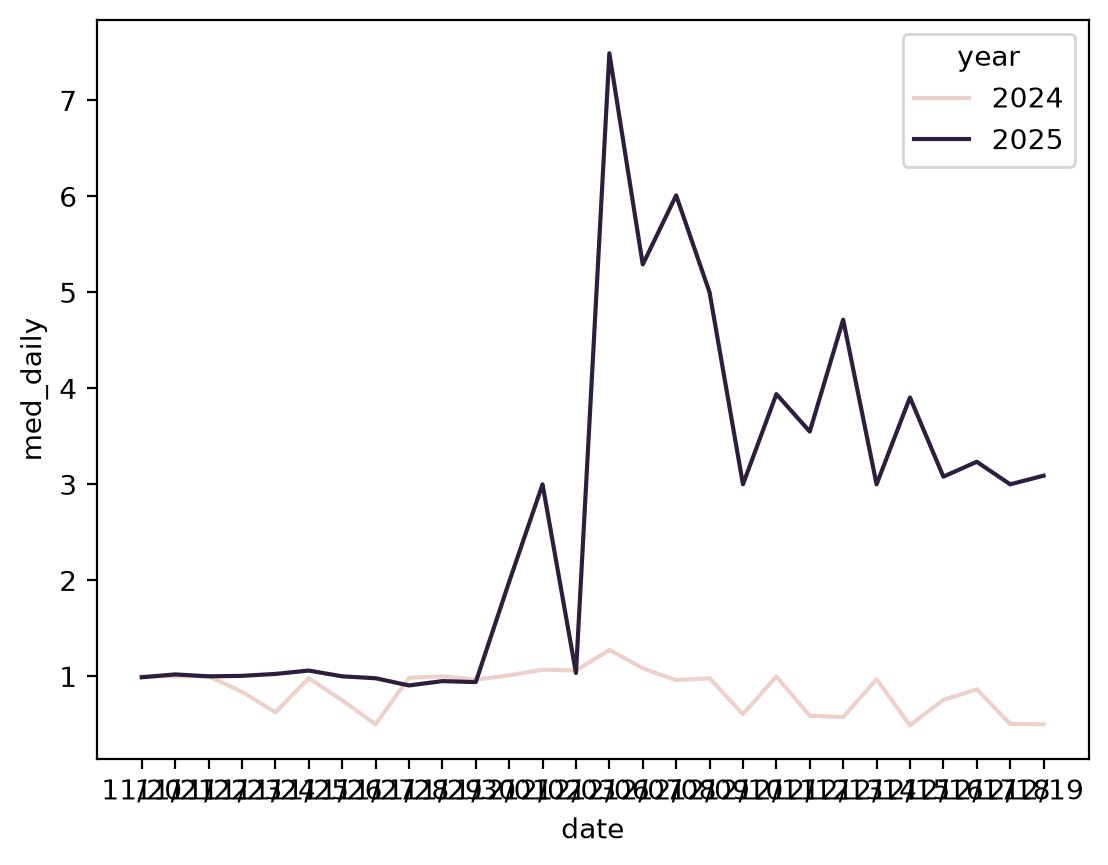

In [41]:
# line plot of NSPIN, by year (2024 and 2025)
fig1 = (
ancillary.query("as_type == 'NSPIN'")
.assign(date = lambda x: x["interval_start_local"].dt.strftime('%m/%d'))
#.assign(mday = lambda x: x['date'].dt.strftime('%m/%d') )
.groupby(['date', 'year'], as_index= False)
.agg(med_daily = ("mcpc", "median"))
)

sns.lineplot(
    data = fig1,
    x = "date",
    y = "med_daily",
    hue = "year"
)

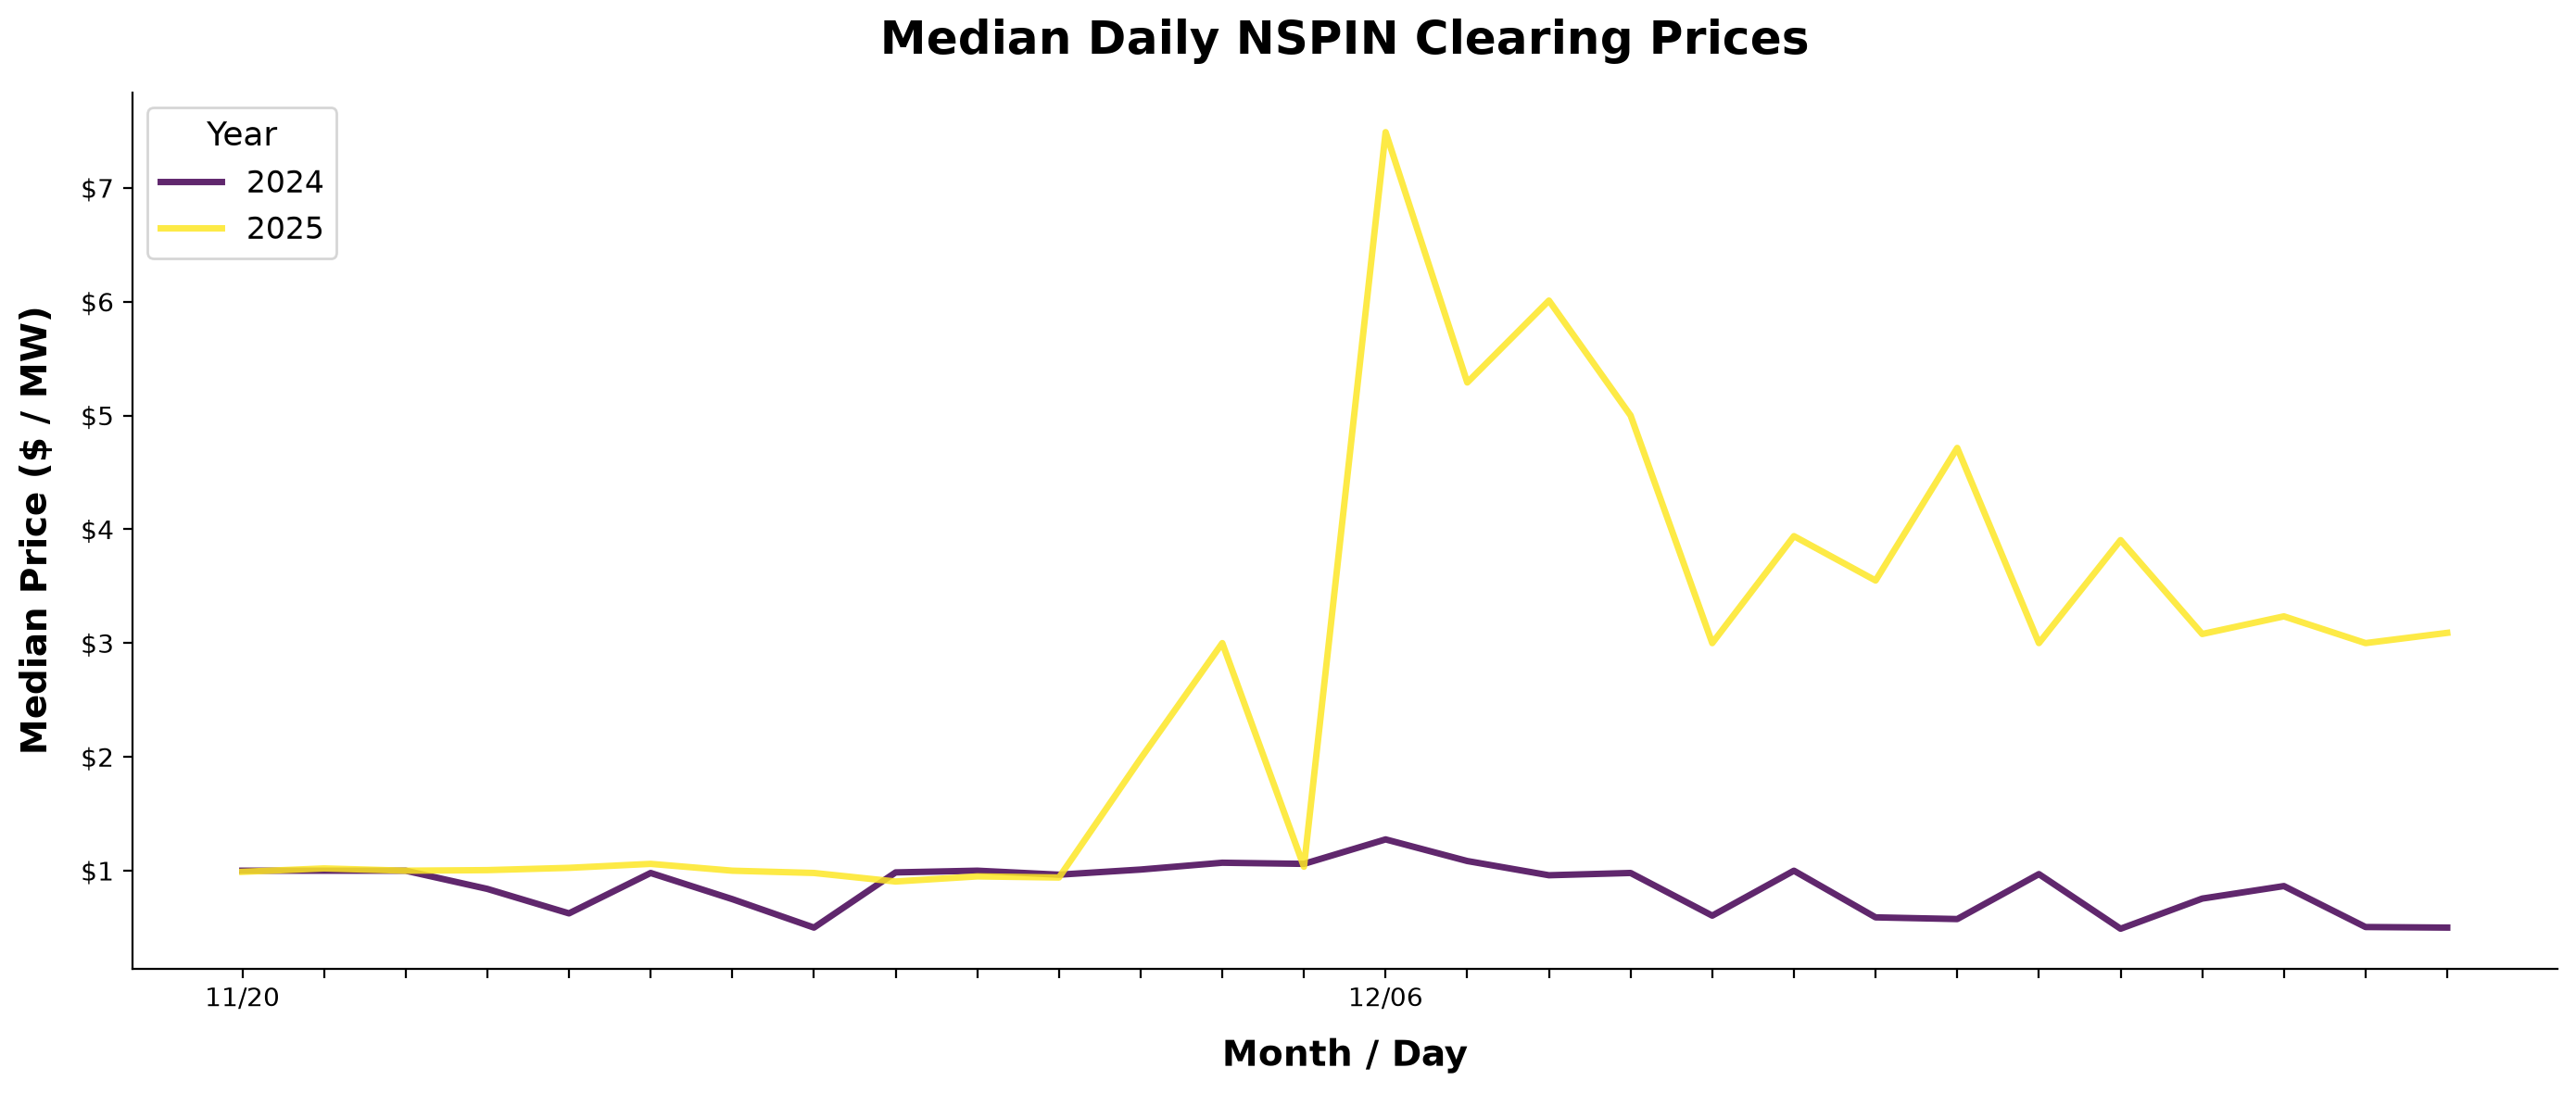

In [48]:
plt.figure(figsize=(14, 6))

# 3. Create the plot with upgraded line aesthetics
ax = sns.lineplot(
    data=fig1,
    x="date",
    y="med_daily",
    hue="year",
    palette="viridis",  # A clean, colorblind-friendly palette
    linewidth=2.5,      # Thicker lines
    alpha=0.85          # Slight transparency so overlapping lines are visible
)

# 4. Add professional titles and labels
plt.title("Median Daily NSPIN Clearing Prices", fontsize=18, fontweight='bold', pad=15)
plt.xlabel("Month / Day", fontsize=14, fontweight='bold', labelpad=10)
plt.ylabel("Median Price ($ / MW)", fontsize=14, fontweight='bold', labelpad=10)


# 5. Format the Y-axis as currency (e.g., $10, $20)
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('${x:,.0f}'))

# 6. Fix overlapping X-axis labels (shows a label every 14 days)
# Adjust the '14' depending on how many total days are in your dataset
for ind, label in enumerate(ax.get_xticklabels()):
    if ind % 14 == 0:  
        label.set_visible(True)
    else:
        label.set_visible(False)

# 7. Clean up the legend and grid
plt.legend(title="Year", title_fontsize='13', fontsize='12', loc='upper left', frameon=True)
sns.despine() # Removes the top and right border spines

plt.tight_layout()